In [25]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Veri setini oku
df = pd.read_csv("gercekci_hayvan_veri_seti.csv")

# İlk 5 satıra bakarak veriyi kontrol et
df.head()

,Ortam_Isisi,Vucut_Isisi,Hareket,Durum
0,37.985527,39.539879,66.511397,Mastitis_Riski
1,38.583350,38.865428,79.889658,Saglikli
2,22.045591,38.326735,66.542918,Saglikli
3,40.985640,40.134444,42.196818,Mastitis_Riski
4,34.696702,39.188858,50.979174,Mastitis_Riski


In [27]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder

# 1. Metin etiketleri sayılara dönüştür (Sağlıklı: 0, Şap: 1 vb.)
le = LabelEncoder()
df['Durum_Kod'] = le.fit_transform(df['Durum'])

# 2. Giriş ve Çıkış verilerini belirle
X = df[['Ortam_Isisi', 'Vucut_Isisi', 'Hareket']] # Girdiler
y = df['Durum_Kod'] # Tahmin edilecek hedef

# 3. Veriyi Eğitim ve Test olarak ikiye böl (%80 eğitim, %20 test)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.20, random_state=42)

In [29]:
from sklearn.ensemble import RandomForestClassifier



# Modeli tanımla ve eğit[cite: 1]

model = RandomForestClassifier(n_estimators=100, random_state=42)

model.fit(X_train, y_train)



print("Model eğitimi tamamlandı!")

Model eğitimi tamamlandı!


                  precision    recall  f1-score   support

  Mastitis_Riski       0.85      0.94      0.89       144
        Saglikli       0.98      0.99      0.98       405
       Sap_Riski       1.00      1.00      1.00        27
Tuberkuloz_Riski       0.83      0.21      0.33        24

        accuracy                           0.94       600
       macro avg       0.92      0.78      0.80       600
    weighted avg       0.94      0.94      0.94       600



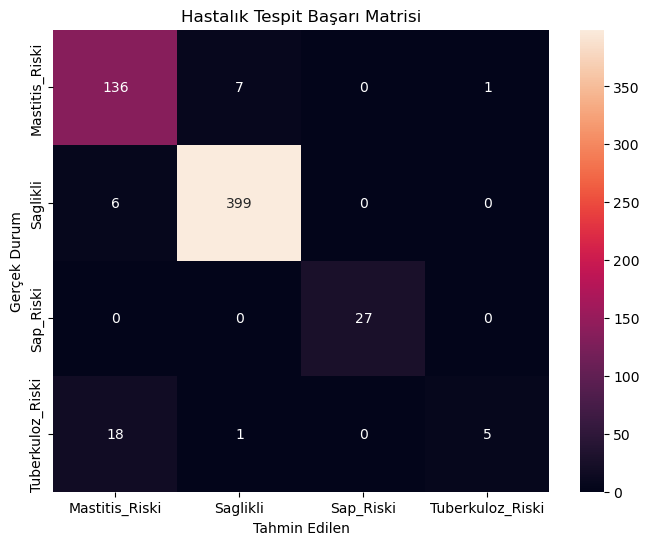

In [31]:
from sklearn.metrics import classification_report, confusion_matrix

# Test verisiyle tahmin yap
y_pred = model.predict(X_test)

# Sonuçları raporla[cite: 1]
print(classification_report(y_test, y_pred, target_names=le.classes_))

# Karmaşıklık Matrisi Görselleştirmesi
plt.figure(figsize=(8,6))
sns.heatmap(confusion_matrix(y_test, y_pred), annot=True, fmt='d', xticklabels=le.classes_, yticklabels=le.classes_)
plt.xlabel('Tahmin Edilen')
plt.ylabel('Gerçek Durum')
plt.title('Hastalık Tespit Başarı Matrisi')
plt.show()

In [33]:
# Yeni bir veri girişi örneği: [Ortam_Isisi, Vucut_Isisi, Hareket]
yeni_hayvan = [[25.0, 39.5, 35.0]] 

# Tahmin yap (Sayısal kod döner: 0, 1, 2...)
tahmin_kod = model.predict(yeni_hayvan)

# Sayısal kodu tekrar metne çevir (Şap, Mastitis vb.)
tahmin_metin = le.inverse_transform(tahmin_kod)

print(f"Sistemin Tahmini: {tahmin_metin[0]}")

Sistemin Tahmini: Mastitis_Riski


C:\Users\nsnry\anaconda3\Lib\site-packages\sklearn\base.py:493: UserWarning: X does not have valid feature names, but RandomForestClassifier was fitted with feature names
  warnings.warn(
